# reading in mutual information score data 

In [1]:
import pandas as pd

BASE = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/calc_files/MI/mi_analysis_results_MI_label_entropy_all_genes_parallel"

normalized_MI_junker = pd.read_csv(f"{BASE}/MI_label_entropy_junker_50_permutations.csv")
normalized_MI_knoblich_day16_1 = pd.read_csv(f"{BASE}/MI_label_entropy_knoblich_day16_1_50_permutations.csv")
normalized_MI_knoblich_day16_2 = pd.read_csv(f"{BASE}/MI_label_entropy_knoblich_day16_2_50_permutations.csv")
normalized_MI_knoblich_day42_1 = pd.read_csv(f"{BASE}/MI_label_entropy_knoblich_day42_1_50_permutations.csv")
normalized_MI_knoblich_day42_2 = pd.read_csv(f"{BASE}/MI_label_entropy_knoblich_day42_2_50_permutations.csv")

normalized_MI_treutlein = pd.read_csv(f"{BASE}/MI_label_entropy_treutlein_50_permutations.csv")
normalized_MI_weinreb = pd.read_csv(f"{BASE}/MI_label_entropy_weinreb_50_permutations.csv")

normalized_MI_you1 = pd.read_csv(f"{BASE}/MI_label_entropy_you1_50_permutations.csv")
normalized_MI_you2 = pd.read_csv(f"{BASE}/MI_label_entropy_you2_50_permutations.csv")
normalized_MI_you3 = pd.read_csv(f"{BASE}/MI_label_entropy_you3_50_permutations.csv")
normalized_MI_you4 = pd.read_csv(f"{BASE}/MI_label_entropy_you4_50_permutations.csv")

# Assign dataset names for the legend
dfs = [
    (normalized_MI_you1, 'HBO3_1'),
    (normalized_MI_you2, 'HBO3_2'),
    (normalized_MI_you3, 'HBO3_3'),
    (normalized_MI_you4, 'HBO3_4'),
    (normalized_MI_knoblich_day16_1, 'HBO2_16_1'),
    (normalized_MI_knoblich_day16_2, 'HBO2_16_2'),
    (normalized_MI_knoblich_day42_1, 'HBO2_42_1'),
    (normalized_MI_knoblich_day42_2, 'HBO2_42_2'),
    (normalized_MI_treutlein, 'HBO1'),
    (normalized_MI_weinreb, 'MHPSC'),
    (normalized_MI_junker, 'ZFL')
]


# Add a 'dataset' column to each dataframe
for df, name in dfs:
    df['dataset'] = name

# Concatenate all dataframes together
all_data = pd.concat([df for df, name in dfs], ignore_index=True)


# Mutual Information Scores across gene categories

In [2]:
all_data = all_data.set_index("gene")

In [3]:
mt_genes = [
    "MT-ND1", "MT-ND2", "MT-CO1", "MT-CO2", "MT-ATP8", "MT-ATP6", "MT-CO3", "MT-ND3", 
    "MT-ND4L", "MT-ND4", "MT-ND5", "MT-ND6", "MT-CYB", "mt-Nd1", "mt-Nd2", "mt-Co1", 
    "mt-Co2", "mt-Atp8", "mt-Atp6", "mt-Co3", "mt-Nd3", "mt-Nd4l", "mt-Nd4", "mt-Nd5", 
    "mt-Nd6", "mt-Cytb", "NC_002333.17", "NC_002333.12", "mt-nd3", "NC_002333.3", 
    "mt-nd4l", "mt-nd4", "NC_002333.16", "NC_002333.15", "mt-nd5", "mt-nd6", "mt-cyb", 
    "NC_002333.22", "NC_002333.10", "NC_002333.4", "NC_002333.19", "mt-nd1", 
    "NC_002333.6", "NC_002333.14", "mt-nd2", "NC_002333.7", "NC_002333.5", 
    "NC_002333.13", "NC_002333.18", "NC_002333.1", "mt-co1", "NC_002333.24"
]

# if the gene is a mitochondrial gene, set is_mitochondrial to True
all_data['is_mitochondrial'] = all_data.index.isin(mt_genes)

In [4]:
autophagy_genes = [
    "ATG5", "ATG7", "BECN1", "MAP1LC3B", "SQSTM1", "GABARAPL1", 
    "ULK1", "WIPI2", "ATG12", "ATG16L1", "VPS34", "UVRAG", 
    "PINK1", "PRKN", "BNIP3", "DRAM1", "GABARAP", "LC3B", 
    "ATG4B", "RUBCN", "FIP200", "AMBRA1"
]

zebrafish_autophagy_genes = [
    "atg5", "atg7", "becn1", "map1lc3b", "sqstm1", "gabarapl1", 
    "ulk1", "wipi2", "atg12", "atg16l1", "pik3c3", "uvrag", 
    "pink1", "parkin", "bnip3", "dram1", "gabarap", "map1lc3b", 
    "atg4b", "rubcn", "rb1cc1", "ambra1"
]

mouse_autophagy_genes = [
    "Atg5", "Atg7", "Becn1", "Map1lc3b", "Sqstm1", "Gabarapl1", 
    "Ulk1", "Wipi2", "Atg12", "Atg16l1", "Pik3c3", "Uvrag", 
    "Pink1", "Prkn", "Bnip3", "Dram1", "Gabarap", "Map1lc3b", 
    "Atg4b", "Rubcn", "Rb1cc1", "Ambra1"
]

autophagy_genes = autophagy_genes + zebrafish_autophagy_genes + mouse_autophagy_genes

all_data['is_autophagy'] = all_data.index.isin(autophagy_genes)

In [5]:
zebrafish_genes = [
    # Oxidative Phosphorylation (OXPHOS) Support Genes
    "ndufs1", "sdha", "uqcrc1", "cox4i1", "atp5f1a",
    
    # Mitochondrial Biogenesis Genes
    "ppargc1a", "tfam", "twinkle", "polg",
    
    # Protein Import Machinery
    "tomm20a", "timm23", "hspa9",
    
    # Mitochondrial Ribosome Components
    "mrpl12", "mrps22",
    
    # Reactive Oxygen Species (ROS) Management
    "sod2", "gpx4a", "prdx3",
    
    # Mitochondrial Dynamics
    "mfn1", "mfn2", "opa1", "dnm1l",
    
    # Apoptosis Regulation
    "bcl2", "cycs",
    
    # Cellular Metabolism
    "idh3a", "cpt1a", "glud1a",
    
    # Mitochondrial Stress Response Genes
    "atf4a", "chop"
]

mouse_genes = [
    # Oxidative Phosphorylation (OXPHOS) Support Genes
    "Ndufs1", "Sdha", "Uqcrc1", "Cox4i1", "Atp5f1a",
    
    # Mitochondrial Biogenesis Genes
    "Ppargc1a", "Tfam", "Twnk", "Polg",
    
    # Protein Import Machinery
    "Tomm20", "Timm23", "Hspa9",
    
    # Mitochondrial Ribosome Components
    "Mrpl12", "Mrps22",
    
    # Reactive Oxygen Species (ROS) Management
    "Sod2", "Gpx4", "Prdx3",
    
    # Mitochondrial Dynamics
    "Mfn1", "Mfn2", "Opa1", "Dnm1l",
    
    # Apoptosis Regulation
    "Bcl2", "Cycs",
    
    # Cellular Metabolism
    "Idh3a", "Cpt1a", "Glud1",
    
    # Mitochondrial Stress Response Genes
    "Atf4", "Chop"
]

mitochondrial_related_genes = [
    # Oxidative Phosphorylation (OXPHOS) Support Genes
    "NDUFS1", "SDHA", "UQCRC1", "COX4I1", "ATP5F1A",
    
    # Mitochondrial Biogenesis Genes
    "PPARGC1A", "TFAM", "TWNK", "POLG",
    
    # Protein Import Machinery
    "TOMM20", "TIMM23", "HSPA9",
    
    # Mitochondrial Ribosome Components
    "MRPL12", "MRPS22",
    
    # Reactive Oxygen Species (ROS) Management
    "SOD2", "GPX4", "PRDX3",
    
    # Mitochondrial Dynamics
    "MFN1", "MFN2", "OPA1", "DNM1L",
    
    # Apoptosis Regulation
    "BCL2", "CYCS",
    
    # Cellular Metabolism
    "IDH3A", "CPT1A", "GLUD1",
    
    # Mitochondrial Stress Response Genes
    "ATF4", "CHOP"
]

mitochondrial_related_genes = mitochondrial_related_genes + zebrafish_genes + mouse_genes

all_data['is_mitochondrial_related'] = False

all_data['is_mitochondrial_related'] = all_data.index.isin(mitochondrial_related_genes)

In [6]:
def assign_gene_set(row):
    if row['is_mitochondrial']:
        return "Mitochondrial genes"
    elif row['is_autophagy']:
        return "Autophagy genes"
    elif row['is_mitochondrial_related']:
        return "Nuclear MT genes"
    else:
        return "All other genes"

all_data['gene_set'] = all_data.apply(assign_gene_set, axis=1)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

HBO3_4_All other genes vs. HBO3_4_Mitochondrial genes: Mann-Whitney-Wilcoxon test two-sided, P_val:5.763e-09 U_stat=1.015e+04
HBO2_16_1_All other genes vs. HBO2_16_1_Mitochondrial genes: Mann-Whitney-Wilcoxon test two-sided, P_val:1.586e-09 U_stat=6.340e+03
HBO3_3_All other genes vs. HBO3_3_Mitochondrial genes: Mann-Whitney-Wilcoxon test two-sided, P_val:7.821e-09 U_stat=1.272e+04
HBO3_1_All other genes vs. HBO3_1_Mitochondrial genes: Mann-Whitney-Wilcoxon test two-sided, P_val:3.296e-09 U_stat=8.615e+03
HBO3_2_All other genes vs. HBO3_2_Mitochondrial genes: Mann-Whitney-Wilcoxon test two-sided, P_val:8.593e-09 U_stat=1.359e+04
HBO2_16_2_All other genes vs. HBO2_16_2_Mitochondrial genes: Mann-Whitney-Wilcoxon test two-sided, P_val:1.306e-09 U_stat=5.310e+03
HBO2_42_1_All other genes vs. HBO2_42_1_

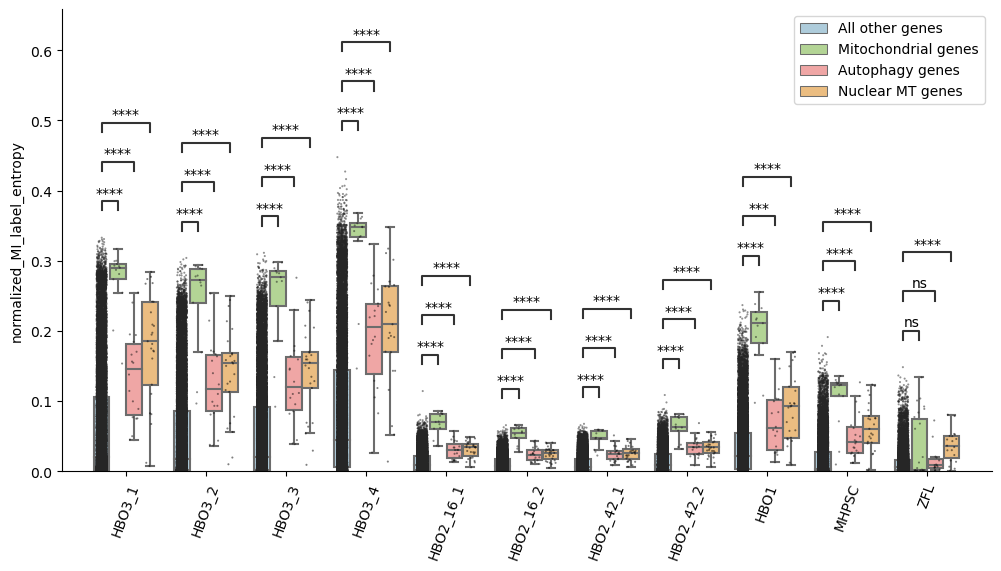

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from statannotations.Annotator import Annotator

# Ensure dataset is ordered and define custom categories for 'gene_set'
dataset_order = [
    "HBO3_1",
    "HBO3_2",
    "HBO3_3",
    "HBO3_4",
    "HBO2_16_1",
    "HBO2_16_2",
    "HBO2_42_1",
    "HBO2_42_2",
    "HBO1",
    "MHPSC",
    "ZFL"
]
gene_set_order = ["All other genes", "Mitochondrial genes", "Autophagy genes", "Nuclear MT genes"]

# Convert columns to categorical for proper ordering
all_data['dataset'] = pd.Categorical(all_data['dataset'], categories=dataset_order, ordered=True)
all_data['gene_set'] = pd.Categorical(all_data['gene_set'], categories=gene_set_order, ordered=True)

# Define color palette
cmap = sns.color_palette("Paired")
custom_palette = [cmap[0], cmap[2], cmap[4], cmap[6]]  # Colors for the gene sets

# Create the boxplot
plt.figure(figsize=(12, 6))
box_plot = sns.boxplot(
    x='dataset',
    y='normalized_MI_label_entropy',
    hue='gene_set',
    data=all_data,
    palette=custom_palette,
    showfliers=False
)


# Add stripplot for data visualization
sns.stripplot(
    x='dataset',
    y="normalized_MI_label_entropy",
    hue='gene_set',
    data=all_data,
    color='black',
    size=1.5,
    alpha=0.5,
    dodge=True,
    jitter=0.25
)

# Remove duplicate legends
handles, labels = box_plot.get_legend_handles_labels()
plt.legend(handles[:4], labels[:4], loc='upper right')

# Remove spines and adjust x-axis labels
sns.despine()
plt.xticks(rotation=70)
plt.xlabel('')
plt.ylim(0, all_data["normalized_MI_label_entropy"].max() + 0.2)

# Generate pairs dynamically for statistical annotations
gene_sets = ["Mitochondrial genes", "Autophagy genes", "Nuclear MT genes"]
pairs = []
for dataset in dataset_order:
    for gene_set in gene_sets:
        pairs.append(((dataset, "All other genes"), (dataset, gene_set)))

# Add statistical annotations
annotator = Annotator(
    box_plot,
    pairs,
    data=all_data,
    x='dataset',
    y='normalized_MI_label_entropy',
    hue='gene_set'
)
annotator.configure(test='Mann-Whitney', text_format='star', loc='inside')
annotator.apply_and_annotate()

# Save and show the plot
plt.savefig(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/all_datasets_mutual_information_all_gene_sets_with_stats.pdf",
    dpi=300,
    bbox_inches='tight'
)
plt.show()



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

HBO3_4_All other genes vs. HBO3_4_Mitochondrial genes: Mann-Whitney-Wilcoxon test two-sided, P_val:5.763e-09 U_stat=1.015e+04
HBO2_16_1_All other genes vs. HBO2_16_1_Mitochondrial genes: Mann-Whitney-Wilcoxon test two-sided, P_val:1.586e-09 U_stat=6.340e+03
HBO3_3_All other genes vs. HBO3_3_Mitochondrial genes: Mann-Whitney-Wilcoxon test two-sided, P_val:7.821e-09 U_stat=1.272e+04
HBO3_1_All other genes vs. HBO3_1_Mitochondrial genes: Mann-Whitney-Wilcoxon test two-sided, P_val:3.296e-09 U_stat=8.615e+03
HBO3_2_All other genes vs. HBO3_2_Mitochondrial genes: Mann-Whitney-Wilcoxon test two-sided, P_val:8.593e-09 U_stat=1.359e+04
HBO2_16_2_All other genes vs. HBO2_16_2_Mitochondrial genes: Mann-Whitney-Wilcoxon test two-sided, P_val:1.306e-09 U_stat=5.310e+03
HBO2_42_1_All other genes vs. HBO2_42_1_

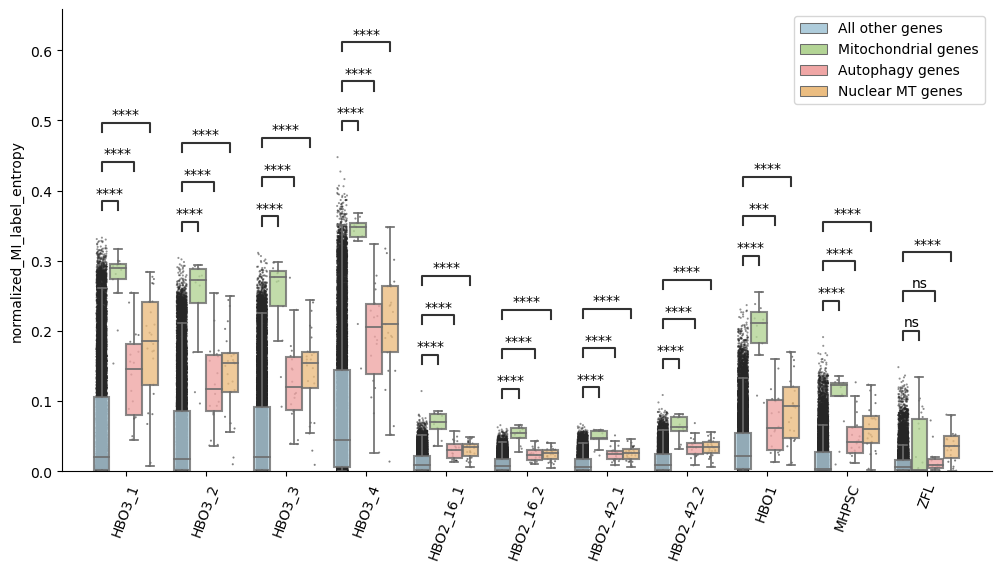

In [9]:
plt.figure(figsize=(12, 6))

# 1. Plot stripplot first
sns.stripplot(
    x='dataset',
    y='normalized_MI_label_entropy',
    hue='gene_set',
    data=all_data,
    color='black',
    size=1.5,
    alpha=0.5,
    dodge=True,
    jitter=0.25,
    zorder=1
)

# 2. Plot boxplot
box_plot = sns.boxplot(
    x='dataset',
    y='normalized_MI_label_entropy',
    hue='gene_set',
    data=all_data,
    palette=custom_palette,
    showfliers=False,
    dodge=True,
    zorder=2,
    boxprops=dict(zorder=2, linewidth=1.5),
    medianprops=dict(linewidth=1.2, zorder=3),
    whiskerprops=dict(linewidth=1.2, zorder=3),
    capprops=dict(linewidth=1.2, zorder=3)
)

# Set transparency only for actual plot boxes
for artist in box_plot.artists:
    artist.set_alpha(0.8)

# Legend
handles, labels = box_plot.get_legend_handles_labels()
plt.legend(handles[:4], labels[:4], loc='upper right')

# Aesthetic
sns.despine()
plt.xticks(rotation=70)
plt.xlabel('')
plt.ylim(0, all_data["normalized_MI_label_entropy"].max() + 0.2)

# Generate pairs dynamically for statistical annotations
gene_sets = ["Mitochondrial genes", "Autophagy genes", "Nuclear MT genes"]
pairs = []
for dataset in dataset_order:
    for gene_set in gene_sets:
        pairs.append(((dataset, "All other genes"), (dataset, gene_set)))

# Add statistical annotations
annotator = Annotator(
    box_plot,
    pairs,
    data=all_data,
    x='dataset',
    y='normalized_MI_label_entropy',
    hue='gene_set'
)
annotator.configure(test='Mann-Whitney', text_format='star', loc='inside')
annotator.apply_and_annotate()

# Save and show
plt.savefig(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/all_datasets_mutual_information_all_gene_sets_with_stats.pdf",
    dpi=300,
    bbox_inches='tight'
)
plt.show()


In [10]:
# only box plot 

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

HBO3_4_All other genes vs. HBO3_4_Mitochondrial genes: Mann-Whitney-Wilcoxon test two-sided, P_val:5.763e-09 U_stat=1.015e+04
HBO2_16_1_All other genes vs. HBO2_16_1_Mitochondrial genes: Mann-Whitney-Wilcoxon test two-sided, P_val:1.586e-09 U_stat=6.340e+03
HBO3_3_All other genes vs. HBO3_3_Mitochondrial genes: Mann-Whitney-Wilcoxon test two-sided, P_val:7.821e-09 U_stat=1.272e+04
HBO3_1_All other genes vs. HBO3_1_Mitochondrial genes: Mann-Whitney-Wilcoxon test two-sided, P_val:3.296e-09 U_stat=8.615e+03
HBO3_2_All other genes vs. HBO3_2_Mitochondrial genes: Mann-Whitney-Wilcoxon test two-sided, P_val:8.593e-09 U_stat=1.359e+04
HBO2_16_2_All other genes vs. HBO2_16_2_Mitochondrial genes: Mann-Whitney-Wilcoxon test two-sided, P_val:1.306e-09 U_stat=5.310e+03
HBO2_42_1_All other genes vs. HBO2_42_1_

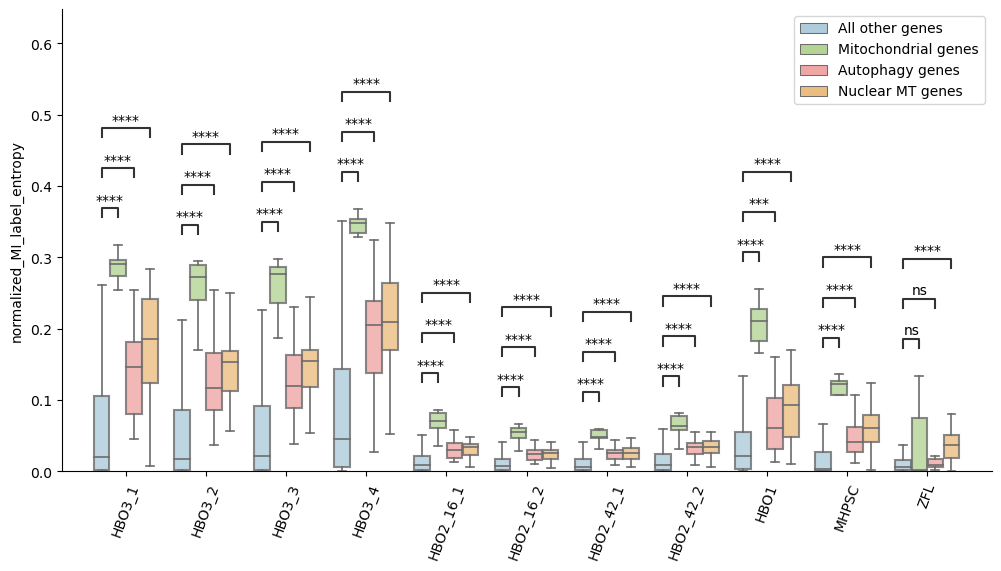

In [11]:
plt.figure(figsize=(12, 6))

# 2. Plot boxplot
box_plot = sns.boxplot(
    x='dataset',
    y='normalized_MI_label_entropy',
    hue='gene_set',
    data=all_data,
    palette=custom_palette,
    showfliers=False,
    dodge=True,
    zorder=2,
    boxprops=dict(zorder=2, linewidth=1.5),
    medianprops=dict(linewidth=1.2, zorder=3),
    whiskerprops=dict(linewidth=1.2, zorder=3),
    capprops=dict(linewidth=1.2, zorder=3)
)

# Set transparency only for actual plot boxes
for artist in box_plot.artists:
    artist.set_alpha(0.8)

# Legend
handles, labels = box_plot.get_legend_handles_labels()
plt.legend(handles[:4], labels[:4], loc='upper right')

# Aesthetic
sns.despine()
plt.xticks(rotation=70)
plt.xlabel('')
plt.ylim(0, all_data["normalized_MI_label_entropy"].max() + 0.2)

# Generate pairs dynamically for statistical annotations
gene_sets = ["Mitochondrial genes", "Autophagy genes", "Nuclear MT genes"]
pairs = []
for dataset in dataset_order:
    for gene_set in gene_sets:
        pairs.append(((dataset, "All other genes"), (dataset, gene_set)))

# Add statistical annotations
annotator = Annotator(
    box_plot,
    pairs,
    data=all_data,
    x='dataset',
    y='normalized_MI_label_entropy',
    hue='gene_set'
)
annotator.configure(test='Mann-Whitney', text_format='star', loc='inside')
annotator.apply_and_annotate()

# Save and show
plt.savefig(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/all_datasets_mutual_information_all_gene_sets_with_stats_only_box_plot.pdf",
    dpi=300,
    bbox_inches='tight'
)
plt.show()
